# Customer Segmentation Analysis

## Business Question
How can we group the customers of our online store by how recently, how often, and how much they buy, so that marketing can treat each group differently?

### Sub-questions
1. Which customer segments exist?
2. Which segments bring the most revenue?
3. Which segments are at risk of lapsing?
4. What marketing action fits each segment?

## Objective
Group the customers of an online store into segments using RFM (Recency, Frequency, Monetary) and K-Means clustering, and recommend a marketing action for each segment.

**Dataset:** Online Retail, UCI Machine Learning Repository (https://archive.ics.uci.edu/dataset/352/online+retail). Each row is one product line in an invoice, so an invoice with 5 products appears as 5 rows.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
os.environ["LOKY_MAX_CPU_COUNT"] = str(max(1, (os.cpu_count() or 2) - 1))  # one core fewer than the computer has, so scikit-learn does not look for the physical core count
import warnings
warnings.filterwarnings("ignore", message="Could not find the number of physical cores")  # hides a harmless Windows warning from scikit-learn
df = pd.read_excel("Online Retail.xlsx")
print(df.shape)
df.head()

(541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [2]:
# Check column types and non-null counts
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


In [3]:
# Count missing values in each column
df.isnull().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [4]:
# Summary statistics for the numeric columns
df.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386048,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


In [5]:
# Find the date range, number of customers, and number of invoices
print(df["InvoiceDate"].min(), "to", df["InvoiceDate"].max())
print(df["CustomerID"].nunique(), "unique customers")
print(df["InvoiceNo"].nunique(), "unique invoices")

2010-12-01 08:26:00 to 2011-12-09 12:50:00
4372 unique customers
25900 unique invoices


### Data Quality Checks
#### Check 1: Invoice numbers and negative quantities

**What I noticed**
- InvoiceNo was loaded as text (object), although invoice numbers look like plain numbers.
- Quantity has negative values (minimum of -80,995).

**What the documentation says** :
The UCI page describes InvoiceNo as a 6-digit number and says this code starts with the letter c it indicates a cancellation.

**Hypothesis to test** :
The text type is caused by invoice numbers that start with a letter, and the negative quantities belong to those cancellation invoices.

**Test** :
Count the invoice numbers that are not all digits, see which letters they start with, and measure what share of the negative-quantity rows they cover.


In [6]:
# Count invoice numbers that contain anything other than digits
(~df["InvoiceNo"].astype(str).str.isdigit()).sum()

np.int64(9291)

In [7]:
# Show which letters those non-digit invoice numbers start with
df[~df["InvoiceNo"].astype(str).str.isdigit()]["InvoiceNo"].astype(str).str[0].value_counts()

InvoiceNo
C    9288
A       3
Name: count, dtype: int64

In [8]:
# Show a sample of the rows with a negative quantity
df[df["Quantity"] < 0].head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
238,C536391,21980,PACK OF 12 RED RETROSPOT TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
239,C536391,21484,CHICK GREY HOT WATER BOTTLE,-12,2010-12-01 10:24:00,3.45,17548.0,United Kingdom
240,C536391,22557,PLASTERS IN TIN VINTAGE PAISLEY,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
241,C536391,22553,PLASTERS IN TIN SKULLS,-24,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
939,C536506,22960,JAM MAKING SET WITH JARS,-6,2010-12-01 12:38:00,4.25,17897.0,United Kingdom


In [9]:
# Share of negative-quantity rows whose invoice number is not all digits
(~df[df["Quantity"] < 0]["InvoiceNo"].astype(str).str.isdigit()).mean()

np.float64(0.8742469879518072)

In [10]:
# Count all rows with a negative quantity
(df["Quantity"] < 0).sum()

np.int64(10624)

In [11]:
# Share of C invoices that have a negative quantity (checks the reverse direction)
(df[df["InvoiceNo"].astype(str).str.startswith("C")]["Quantity"] < 0).mean()

np.float64(1.0)

In [12]:
# Show the rows whose invoice number starts with A
df[df["InvoiceNo"].astype(str).str.startswith("A")]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
299982,A563185,B,Adjust bad debt,1,2011-08-12 14:50:00,11062.06,NaN,United Kingdom
299983,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,NaN,United Kingdom
299984,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,NaN,United Kingdom


In [13]:
# Show a sample of negative-quantity rows with a normal (all-digit) invoice number
df[(df["Quantity"] < 0) & (df["InvoiceNo"].astype(str).str.isdigit())].head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
2406,536589,21777,NaN,-10,2010-12-01 16:50:00,0.0,NaN,United Kingdom
4347,536764,84952C,NaN,-38,2010-12-02 14:42:00,0.0,NaN,United Kingdom
7188,536996,22712,NaN,-20,2010-12-03 15:30:00,0.0,NaN,United Kingdom
7189,536997,22028,NaN,-20,2010-12-03 15:30:00,0.0,NaN,United Kingdom
7190,536998,85067,NaN,-6,2010-12-03 15:30:00,0.0,NaN,United Kingdom
7192,537000,21414,NaN,-22,2010-12-03 15:32:00,0.0,NaN,United Kingdom
7193,537001,21653,NaN,-6,2010-12-03 15:33:00,0.0,NaN,United Kingdom
7195,537003,85126,NaN,-2,2010-12-03 15:33:00,0.0,NaN,United Kingdom
7196,537004,21814,NaN,-30,2010-12-03 15:34:00,0.0,NaN,United Kingdom
7197,537005,21692,NaN,-70,2010-12-03 15:35:00,0.0,NaN,United Kingdom


In [14]:
# Build a filter for negative-quantity rows with a normal all-digit invoice number, then count them
mask = (df["Quantity"] < 0) & (df["InvoiceNo"].astype(str).str.isdigit())
mask.sum()

np.int64(1336)

In [15]:
# Share of those rows with a unit price of zero
(df[mask]["UnitPrice"] == 0).mean()

np.float64(1.0)

In [16]:
# Share of those rows with no CustomerID
df[mask]["CustomerID"].isnull().mean()

np.float64(1.0)

In [17]:
#How many cancellations belong to known customers
# Count C rows, and how many of them have a CustomerID
c_rows = df[df["InvoiceNo"].astype(str).str.startswith("C")]
print(len(c_rows), c_rows["CustomerID"].notnull().sum())

9288 8905


In [18]:
# Number of distinct customers who have at least one cancellation
c_rows["CustomerID"].nunique()

1589

In [19]:
# Share of all customers in the data who have at least one cancellation
c_rows["CustomerID"].nunique() / df["CustomerID"].nunique()

0.3634492223238792

In [20]:
# Compare the total value of cancelled rows with the total value of sales (rows with a CustomerID only)
known = df[df["CustomerID"].notnull()]
cancelled = known[known["InvoiceNo"].astype(str).str.startswith("C")]
sales = known[known["Quantity"] > 0]
cancelled_value = (cancelled["Quantity"] * cancelled["UnitPrice"]).sum()
sales_value = (sales["Quantity"] * sales["UnitPrice"]).sum()
print(cancelled_value, sales_value, abs(cancelled_value) / sales_value)

-611342.0900000001 8911407.904 0.06860218908008817


In [21]:
# For each customer with a CustomerID, compare total purchases with total cancelled value
known = df[df["CustomerID"].notnull()].copy()
known["value"] = known["Quantity"] * known["UnitPrice"]
purchases = known[known["Quantity"] > 0].groupby("CustomerID")["value"].sum()
cancels = known[known["InvoiceNo"].astype(str).str.startswith("C")].groupby("CustomerID")["value"].sum().abs()
ratio = (cancels / purchases).dropna()
ratio.describe()

count    1556.000000
mean        0.110602
std         1.458366
min         0.000082
25%         0.009124
50%         0.021443
75%         0.054337
max        57.050667
Name: value, dtype: float64

In [22]:
# Whether the orginal purcchases of each c still exists in the data
# Check, for each cancellation, whether an earlier purchase exists, and whether its quantity covers the cancelled quantity
known = df[df["CustomerID"].notnull()]
c_rows = known[known["InvoiceNo"].astype(str).str.startswith("C")].reset_index()
buys = known[known["Quantity"] > 0][["CustomerID", "StockCode", "InvoiceDate", "Quantity"]]
merged = c_rows.merge(buys, on=["CustomerID", "StockCode"], suffixes=("_cancel", "_buy"))
earlier = merged[merged["InvoiceDate_buy"] <= merged["InvoiceDate_cancel"]]
any_match = earlier["index"].nunique()
enough = earlier[earlier["Quantity_buy"] >= -earlier["Quantity_cancel"]]["index"].nunique()
exact = earlier[earlier["Quantity_buy"] == -earlier["Quantity_cancel"]]["index"].nunique()
print(len(c_rows), any_match, enough, exact)

8905 7599 7511 2937


In [23]:
# Compute each customer's net spend (purchases minus cancellations) and count customers at zero or below
known = df[df["CustomerID"].notnull()].copy()
known["value"] = known["Quantity"] * known["UnitPrice"]
net = known.groupby("CustomerID")["value"].sum().round(2)
print((net <= 0).sum(), len(net))

55 4372


In [24]:
# Count customers who cancelled more than half, and more than all, of what they purchaseds
print((ratio > 0.5).sum(), (ratio > 1).sum())

39 8


### Check 1 result

- 9,291 rows have an invoice number that is not all digits: 9,288 start with C and 3 start with A.
- Every C row has a negative quantity. They make up 9,288 of the 10,624 negative-quantity rows (87.4%). This matches the UCI documentation (in the data, the letter is uppercase).
- The 3 A rows have StockCode B, the description "Adjust bad debt", no CustomerID, and prices of £11,062.06 and -£11,062.06. They are accounting entries, not purchases.
- The other 1,336 negative-quantity rows have normal invoice numbers. All of them have a unit price of 0 and no CustomerID.
- 8,905 of the 9,288 C rows (95.9%) belong to a known customer, and 1,589 customers (36.3%) have at least one cancellation.
- For rows with a CustomerID, the cancelled value is £611,342.09, which is 6.9% of the £8,911,407.90 in sales.
- Among the 1,556 customers with both purchases and cancellations, the median customer cancelled 2.1% of what they bought and 75% cancelled 5.4% or less. 39 cancelled more than half and 8 cancelled more than all of it.
- 7,599 of the 8,905 C rows (85.3%) have an earlier purchase of the same product by the same customer. Only 7,511 (84.3%) have a single purchase row large enough to cover the cancelled quantity, and 2,937 (33.0%) match exactly. These are lower bounds, because each cancellation was compared with one purchase row at a time.
- If cancellations were subtracted from spending, 55 of 4,372 customers (1.3%) would have a net spend at or below zero.

### Check 2: Zero and negative prices

**What I noticed**

`UnitPrice` has a minimum of -11,062.06 and a maximum of 38,970, while 75% of rows cost 4.13 or less.

**Test** :
Count rows with a zero or negative price, look at the highest prices, and check whether zero-price rows have a CustomerID.

In [25]:
# Count rows with a zero price, and how many of them have a positive quantity
print((df["UnitPrice"] == 0).sum(), ((df["UnitPrice"] == 0) & (df["Quantity"] > 0)).sum())

2515 1179


In [26]:
# Count rows with a negative price
(df["UnitPrice"] < 0).sum()

np.int64(2)

In [27]:
# Show the 10 highest unit prices
df.sort_values("UnitPrice", ascending=False).head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
222681,C556445,M,Manual,-1,2011-06-10 15:31:00,38970.00,15098.0,United Kingdom
524602,C580605,AMAZONFEE,AMAZON FEE,-1,2011-12-05 11:36:00,17836.46,NaN,United Kingdom
43702,C540117,AMAZONFEE,AMAZON FEE,-1,2011-01-05 09:55:00,16888.02,NaN,United Kingdom
43703,C540118,AMAZONFEE,AMAZON FEE,-1,2011-01-05 09:57:00,16453.71,NaN,United Kingdom
16356,C537651,AMAZONFEE,AMAZON FEE,-1,2010-12-07 15:49:00,13541.33,NaN,United Kingdom
15016,C537630,AMAZONFEE,AMAZON FEE,-1,2010-12-07 15:04:00,13541.33,NaN,United Kingdom
15017,537632,AMAZONFEE,AMAZON FEE,1,2010-12-07 15:08:00,13541.33,NaN,United Kingdom
16232,C537644,AMAZONFEE,AMAZON FEE,-1,2010-12-07 15:34:00,13474.79,NaN,United Kingdom
524601,C580604,AMAZONFEE,AMAZON FEE,-1,2011-12-05 11:35:00,11586.50,NaN,United Kingdom
299982,A563185,B,Adjust bad debt,1,2011-08-12 14:50:00,11062.06,NaN,United Kingdom


In [28]:
# Share of zero-price rows that have no CustomerID
(df[df["UnitPrice"] == 0]["CustomerID"].isnull()).mean()

np.float64(0.9840954274353877)

In [29]:
# Show stock codes that do not match the documented product format, with their descriptions
codes = df["StockCode"].astype(str)
non_product = df[~codes.str.match(r"^\d{5}[A-Za-z]*$")]
print(len(non_product))
non_product.groupby(["StockCode", "Description"]).size().sort_values(ascending=False).head(15)

2995


StockCode     Description                       
POST          POSTAGE                               1252
DOT           DOTCOM POSTAGE                         709
M             Manual                                 571
C2            CARRIAGE                               143
D             Discount                                77
S             SAMPLES                                 63
BANK CHARGES  Bank Charges                            37
AMAZONFEE     AMAZON FEE                              34
CRUK          CRUK Commission                         16
DCGSSGIRL     GIRLS PARTY BAG                         13
DCGSSBOY      BOYS PARTY BAG                          11
gift_0001_20  Dotcomgiftshop Gift Voucher £20.00       9
gift_0001_10  Dotcomgiftshop Gift Voucher £10.00       8
gift_0001_30  Dotcomgiftshop Gift Voucher £30.00       7
DCGS0003      BOXED GLASS ASHTRAY                      4
dtype: int64

In [30]:
# Show the odd stock codes (first 40), including rows with no description
odd_codes = df[~df["StockCode"].astype(str).str.match(r"^\d{5}[A-Za-z]*$")]
odd_codes.groupby(["StockCode", "Description"], dropna=False).size().sort_values(ascending=False).head(40)

StockCode     Description                        
POST          POSTAGE                                1252
DOT           DOTCOM POSTAGE                          709
M             Manual                                  571
C2            CARRIAGE                                143
D             Discount                                 77
S             SAMPLES                                  63
BANK CHARGES  Bank Charges                             37
AMAZONFEE     AMAZON FEE                               34
CRUK          CRUK Commission                          16
DCGSSGIRL     GIRLS PARTY BAG                          13
DCGSSBOY      BOYS PARTY BAG                           11
gift_0001_20  Dotcomgiftshop Gift Voucher £20.00        9
gift_0001_10  Dotcomgiftshop Gift Voucher £10.00        8
gift_0001_30  Dotcomgiftshop Gift Voucher £30.00        7
DCGS0003      BOXED GLASS ASHTRAY                       4
PADS          PADS TO MATCH ALL CUSHIONS                4
POST          NaN     

In [31]:
# For the odd stock codes: number of rows and share of sales value (rows with a CustomerID, positive quantity and price)
known_pos = df[(df["CustomerID"].notnull()) & (df["Quantity"] > 0) & (df["UnitPrice"] > 0)].copy()
known_pos["value"] = known_pos["Quantity"] * known_pos["UnitPrice"]
odd = ~known_pos["StockCode"].astype(str).str.match(r"^\d{5}[A-Za-z]*$")
print(odd.sum(), known_pos[odd]["value"].sum() / known_pos["value"].sum())

1547 0.016870651149580685


### Check 2 result
- 2,515 rows have a unit price of zero. 1,336 of them are the rows with a negative quantity and a normal invoice number found in Check 1. The other 1,179 have a positive quantity. 98.4% of all zero-price rows have no CustomerID.
- 2 rows have a negative price: the two bad debt adjustment rows (-£11,062.06) from Check 1.
- The 10 highest unit prices (up to £38,970) all belong to the stock codes M (Manual), AMAZONFEE, and B (Adjust bad debt), not to products.
- 2,995 rows have a stock code that does not match the documented product format (5 digits, optionally followed by letters). Most are postage and carriage (POST 1,252, DOT 709, C2 143), Manual (571), Discount (77), Samples (63), and fees (Bank Charges 37, Amazon Fee 34, CRUK Commission 16). Others have product-like descriptions: gift vouchers, party bags, and DCGS codes. The list shows all but 2 of the 2,995 rows.
- Among rows with a CustomerID, positive quantity, and positive price, these odd stock codes are 1,547 rows and 1.7% of sales value.

### Check 3: Duplicate rows

**Test**
Count rows that are exact copies of another row.

In [32]:
# Count fully duplicated rows
df.duplicated().sum()

np.int64(5268)

In [33]:
# Share of duplicate copies that have a CustomerID, then a sample of duplicated rows
print(df[df.duplicated()]["CustomerID"].notnull().mean())
df[df.duplicated(keep=False)].sort_values(["InvoiceNo", "StockCode"]).head(10)

0.991837509491268


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
494,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
485,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
489,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
521,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
537,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
565,536412,21448,12 DAISY PEGS IN WOOD BOX,2,2010-12-01 11:49:00,1.65,17920.0,United Kingdom
578,536412,21448,12 DAISY PEGS IN WOOD BOX,1,2010-12-01 11:49:00,1.65,17920.0,United Kingdom


In [34]:
# Duplicate copies with a CustomerID, positive quantity and price: number of rows and share of sales value
dups = df[df.duplicated()]
d = dups[(dups["CustomerID"].notnull()) & (dups["Quantity"] > 0) & (dups["UnitPrice"] > 0)]
base = df[(df["CustomerID"].notnull()) & (df["Quantity"] > 0) & (df["UnitPrice"] > 0)]
print(len(d), (d["Quantity"] * d["UnitPrice"]).sum() / (base["Quantity"] * base["UnitPrice"]).sum())

5192 0.0027155091833623696


### Check 3 result

- 5,268 rows are exact copies of an earlier row in all eight columns.
- 99.2% of the copies have a CustomerID. Frequency counts unique invoices and Recency uses dates, so duplicates can only affect Monetary.
- In the sample, the copies are pairs with the same invoice, product, time, price, and quantity. The same product also appears on separate lines of one invoice with different quantities, so some exact duplicates could be genuine repeated lines.
- Copies with a CustomerID, positive quantity, and positive price: 5,192 rows, worth 0.3% of sales value.

### Check 4: Missing CustomerID

**What I noticed** :
CustomerID is missing in 135,080 of 541,909 rows (24.9%). RFM is calculated per customer, so rows without one cannot be used.

**Test** :
Check how much of the sales value these rows hold, using rows with a positive quantity and a positive price.

In [35]:
# Among valid sales rows: count and share with no CustomerID, and their share of sales value
pos = df[(df["Quantity"] > 0) & (df["UnitPrice"] > 0)].copy()
pos["value"] = pos["Quantity"] * pos["UnitPrice"]
missing = pos["CustomerID"].isnull()
print(missing.sum(), missing.mean(), pos[missing]["value"].sum() / pos["value"].sum())

132220 0.24942275478019407 0.16455690920262017


In [36]:
# Among rows with a stock code in the product format, positive quantity and price: share with no CustomerID, and their share of sales value
pos = df[(df["Quantity"] > 0) & (df["UnitPrice"] > 0)].copy()
pos["value"] = pos["Quantity"] * pos["UnitPrice"]
prod = pos[pos["StockCode"].astype(str).str.match(r"^\d{5}[A-Za-z]*$")]
no_id = prod["CustomerID"].isnull()
print(no_id.mean(), prod[no_id]["value"].sum() / prod["value"].sum())

0.24897058126865318 0.14701225507797214


### Check 4 result

- CustomerID is missing in 135,080 of 541,909 rows (24.9%).
- Among rows with a normal product code, a positive quantity, and a positive price, 24.9% have no CustomerID, and they hold 14.7% of sales value. Including non-product codes, the value share was 16.5%.
- RFM is calculated per customer, so rows without a CustomerID cannot be used. About 14.7% of sales value is therefore outside the segmentation.

### Check 5: Fully cancelled orders

**What I noticed:** `describe()` showed a minimum Quantity of -80,995 and a maximum of 80,995, the same size in both directions.

**Test:** show the rows with that quantity, find the largest cancellations by value, and measure how many cancellations exactly reverse an earlier purchase and how many purchase invoices are fully reversed.

In [37]:
# Show the rows with the largest quantities, positive and negative
df[df["Quantity"].abs() == 80995]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
540421,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2011-12-09 09:15:00,2.08,16446.0,United Kingdom
540422,C581484,23843,"PAPER CRAFT , LITTLE BIRDIE",-80995,2011-12-09 09:27:00,2.08,16446.0,United Kingdom


In [38]:
# Show the 10 largest cancellations by value (rows with a CustomerID), and their share of all cancelled value
known = df[df["CustomerID"].notnull()].copy()
known["value"] = known["Quantity"] * known["UnitPrice"]
c = known[known["InvoiceNo"].astype(str).str.startswith("C")]
top = c.sort_values("value").head(10)
print(top["value"].sum() / c["value"].sum())
top[["InvoiceNo", "StockCode", "Description", "Quantity", "UnitPrice", "CustomerID", "value"]]

0.5369973789961034


,InvoiceNo,StockCode,Description,Quantity,UnitPrice,CustomerID,value
540422,C581484,23843,"PAPER CRAFT , LITTLE BIRDIE",-80995,2.08,16446.0,-168469.60
61624,C541433,23166,MEDIUM CERAMIC TOP STORAGE JAR,-74215,1.04,12346.0,-77183.60
222681,C556445,M,Manual,-1,38970.00,15098.0,-38970.00
422375,C573079,M,Manual,-2,4161.06,12536.0,-8322.12
173277,C551685,POST,POSTAGE,-1,8142.75,16029.0,-8142.75
173391,C551699,M,Manual,-1,6930.00,16029.0,-6930.00
160145,C550456,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,-3114,2.10,15749.0,-6539.40
160143,C550456,85123A,WHITE HANGING HEART T-LIGHT HOLDER,-1930,2.55,15749.0,-4921.50
160141,C550456,48185,DOORMAT FAIRY CAKE,-670,6.75,15749.0,-4522.50
268027,C560372,M,Manual,-1,4287.63,17448.0,-4287.63


In [39]:
# Count cancellations that exactly reverse an earlier purchase (same customer, product, quantity, and price), and their share of cancelled value
buys = known[known["Quantity"] > 0][["CustomerID", "StockCode", "UnitPrice", "Quantity", "InvoiceDate"]]
cc = c.reset_index()
cc["Quantity_pos"] = -cc["Quantity"]
m = cc.merge(buys, left_on=["CustomerID", "StockCode", "UnitPrice", "Quantity_pos"], right_on=["CustomerID", "StockCode", "UnitPrice", "Quantity"], suffixes=("_c", "_b"))
m = m[m["InvoiceDate_b"] <= m["InvoiceDate_c"]]
exact = cc[cc["index"].isin(m["index"].unique())]
print(len(exact), exact["value"].sum() / cc["value"].sum())

2817 0.6599959116179944


In [40]:
# Measure how many purchase invoices are fully reversed by exact cancellations (an upper estimate)
k = df[df["CustomerID"].notnull() & (df["UnitPrice"] > 0)]
buys = k[k["Quantity"] > 0][["InvoiceNo", "CustomerID", "StockCode", "UnitPrice", "Quantity", "InvoiceDate"]].reset_index()
canc = k[k["InvoiceNo"].astype(str).str.startswith("C")][["CustomerID", "StockCode", "UnitPrice", "Quantity", "InvoiceDate"]].copy()
canc["Quantity"] = -canc["Quantity"]
m = buys.merge(canc, on=["CustomerID", "StockCode", "UnitPrice", "Quantity"], suffixes=("_b", "_c"))
m = m[m["InvoiceDate_c"] >= m["InvoiceDate_b"]]
buys["line_reversed"] = buys["index"].isin(m["index"].unique())
inv = buys.groupby("InvoiceNo").agg(CustomerID=("CustomerID", "first"), reversed=("line_reversed", "all"))
print(inv["reversed"].sum(), len(inv), inv["reversed"].mean())
per_cust = inv.groupby("CustomerID")["reversed"].agg(["sum", "count"])
print((per_cust["sum"] > 0).sum(), (per_cust["sum"] == per_cust["count"]).sum(), len(per_cust))

166 18532 0.008957478955320527
115 11 4338


In [41]:
# Count customers whose most recent purchase date changes if fully reversed invoices are ignored
buys["inv_reversed"] = buys["InvoiceNo"].map(inv["reversed"])
last_all = buys.groupby("CustomerID")["InvoiceDate"].max()
last_kept = buys[~buys["inv_reversed"]].groupby("CustomerID")["InvoiceDate"].max()
print((last_all.reindex(last_kept.index) != last_kept).sum())

17


In [42]:
# Re-check the two key cancellation shares after leaving out the service stock codes
service_codes = ["POST", "DOT", "M", "C2", "D", "S", "BANK CHARGES", "AMAZONFEE", "CRUK"]
kp = df[df["CustomerID"].notnull() & (df["UnitPrice"] > 0) & ~df["StockCode"].astype(str).isin(service_codes)].copy()
kp["value"] = kp["Quantity"] * kp["UnitPrice"]
cp = kp[kp["InvoiceNo"].astype(str).str.startswith("C")]
top10_share = cp.sort_values("value").head(10)["value"].sum() / cp["value"].sum()
buys = kp[kp["Quantity"] > 0][["CustomerID", "StockCode", "UnitPrice", "Quantity", "InvoiceDate"]]
cc = cp.reset_index()
cc["Quantity_pos"] = -cc["Quantity"]
m = cc.merge(buys, left_on=["CustomerID", "StockCode", "UnitPrice", "Quantity_pos"], right_on=["CustomerID", "StockCode", "UnitPrice", "Quantity"], suffixes=("_c", "_b"))
m = m[m["InvoiceDate_b"] <= m["InvoiceDate_c"]]
exact = cc[cc["index"].isin(m["index"].unique())]
print(top10_share, len(exact), exact["value"].sum() / cc["value"].sum())

0.5833552222325252 2773 0.8200103485782866


### Check 5 result

**In short:** a few very large cancellations hold much of the cancelled value, and many cancellations simply undo an earlier purchase. Orders cancelled in full affect only a small number of customers.
- **Largest cancellation:** invoice C581484. Customer 16446 cancelled 80,995 units of product 23843 (£168,469.60), 12 minutes after buying exactly that quantity on invoice 581483.
- **The 10 largest cancellations** hold 53.7% of cancelled value (rows with a CustomerID). Five of them are postage (POST) or manual adjustment (M) entries.
- **2,817 of 8,905 cancellation rows (31.6%)** exactly undo an earlier purchase (same customer, product, quantity, and price). They hold 66.0% of cancelled value.
- **Same measures, product rows only.** Leaving out the service stock codes from Decision 4 (POST, DOT, M and so on), and using only rows with a CustomerID and a price above zero, the 10 largest cancellations hold 58.3% of cancelled value, and 2,773 cancellation rows exactly undo an earlier purchase, holding 82.0% of cancelled value. Nothing has been removed from the data yet. This only checks that the result holds when looking at product rows.
    
**Orders cancelled in full**

An invoice is "fully reversed" when every line on it has a matching cancellation: same customer, same product, same quantity, same price, and dated on or after the purchase. The data does not link a cancellation to its original invoice, so this match is the best available.

- **166 of 18,532 purchase invoices (0.9%)** are fully reversed. The true number could be higher or lower:
  - *Too high:* if a customer bought the same product at the same quantity and price on two invoices and cancelled only once, both purchases look reversed.
  - *Too low:* a purchase cancelled in several smaller parts, cancelled at a different price, or cancelled on a row with no CustomerID is not found.
  - These are limits of how the match works. I did not measure how often each happens.
- **Frequency (number of orders):** 115 of 4,338 customers (2.7%) have at least one fully reversed invoice. The customer table counts it as an order, so their Frequency may be too high.
- **Recency (days since the last purchase):** 28 customers (0.6%) are affected.
  - 17 customers: their most recent purchase was cancelled in full, so they look like they bought more recently than they did.
  - 11 customers: every one of their orders was cancelled in full, so no kept purchase remains.

These counts use purchase rows with a CustomerID, a positive quantity, and a positive price, so the customer total (4,338) differs from the 4,372 in the full data.

### Decision 1: how to treat cancellations

**The question:** a cancellation row (negative quantity) reverses a sale. Should it count in a customer's spending?

- **Option A: exclude cancellations.** A customer's spending is the value of their purchases only.
- **Option B: subtract cancellations.** A customer's spending is the value of their purchases minus the value of their cancellations.

**Decision: Option B.**

**Why:**
- **Check 1:** cancellations are a modest share of sales (6.9%), and the typical customer who cancels cancelled little (2.1% of what they bought).
- **Check 5:** the cancelled value is concentrated. On product rows, 82.0% of it comes from cancellations that exactly undo an earlier purchase.
- **Option A** drops the cancellation but keeps the original purchase, so a cancelled order still counts as spending: customer 16446's £168,469.60 order, cancelled 12 minutes later, would stay in their total. A cancelled order is not spending, so **Option B** is the more accurate measure.
  
**Cost:** 55 of 4,372 customers (1.3%) end up with spending of zero or below on the raw data and are left out of the segmentation. The Verification step reports the number on the cleaned data.

**How the customer measures are built**
- Frequency: the number of different purchase invoices (cancellation invoices are not orders)
- Recency: days since the last purchase
- Monetary: the value of purchase rows plus the value of cancellation rows (which is negative)

**Rows removed by this decision:** the 3 bad debt rows (invoice numbers starting with A) and the 1,336 negative-quantity rows with a zero price and no CustomerID. Cancellation rows are kept.

**Limitations**
- An order cancelled in full still counts as an order. About 115 customers (2.7%) are affected for Frequency and about 28 (0.6%) for Recency (Check 5). These shares are small, so I keep both measures unchanged and list this as a limitation.
- 14.7% of cancellations have no earlier purchase of that product in the data, so they reduce spending without a matching purchase.

**Planned check:** Options A and B give different spending for some customers. After building the customer table, I will run the segmentation both ways and count how many customers end up in a different segment. If very few do, the choice between A and B does not change the conclusions.

**Follow-up:** the Robustness Check section at the end tested whether this choice changes the segments.

**Where this is applied:** in the Data Cleaning section later.

### Decisions 2 to 6: other cleaning rules

The rules are applied in this order in the Data Cleaning section. Every rule also applies to cancellation rows.

2. **Remove rows with no CustomerID** (Check 4). The customer measures need a customer. These rows hold 14.7% of sales value, which stays outside the segmentation.
3. **Remove rows with a unit price of zero or below** (Check 2). 2,515 rows have a price of zero (98.4% of them have no CustomerID), and 2 have a negative price (the bad debt rows).
4. **Remove service and adjustment stock codes** (Check 2): POST, DOT, C2, M, D, S, BANK CHARGES, AMAZONFEE, CRUK. Judging by their descriptions, these are postage, fees, and adjustments, not products. All stock codes outside the product format are 1.7% of sales value. Limitation: Monetary leaves out postage that customers also paid.
5. **Remove exact duplicate rows** (Check 3). 5,268 rows are identical to an earlier row. They are worth 0.3% of sales value, and I cannot tell whether they are errors or genuine repeated lines.
6. **Fix data types and text, and add Revenue.** CustomerID becomes a whole number (it was a decimal, because of the missing values). InvoiceNo and StockCode become text (StockCode mixed numbers and text). Extra spaces around Description are removed. Revenue is Quantity × UnitPrice for each row, negative for cancellation rows.

### Cleaning 

In [43]:
# Apply the cleaning decisions in order and record the row count after each step
df_clean = df.copy()
log = [("Start", len(df_clean))]

# Decision 1: remove bad debt adjustments (InvoiceNo starts with A)
df_clean = df_clean[~df_clean["InvoiceNo"].astype(str).str.startswith("A")]
log.append(("Remove A invoices (bad debt)", len(df_clean)))

# Decision 1: remove negative quantities that are not cancellation invoices (cancellations are kept)
is_cancel = df_clean["InvoiceNo"].astype(str).str.startswith("C")
df_clean = df_clean[(df_clean["Quantity"] > 0) | is_cancel]
log.append(("Remove negative quantities outside C invoices", len(df_clean)))

# Decision 2: remove rows with no CustomerID
df_clean = df_clean[df_clean["CustomerID"].notnull()]
log.append(("Remove rows with no CustomerID", len(df_clean)))

# Decision 3: remove rows with a unit price of zero or below
df_clean = df_clean[df_clean["UnitPrice"] > 0]
log.append(("Remove prices of zero or below", len(df_clean)))

# Decision 4: remove service and adjustment stock codes
non_product_codes = ["POST", "DOT", "M", "C2", "D", "S", "BANK CHARGES", "AMAZONFEE", "CRUK"]
df_clean = df_clean[~df_clean["StockCode"].astype(str).isin(non_product_codes)]
log.append(("Remove service and adjustment stock codes", len(df_clean)))

# Decision 5: remove exact duplicate rows
df_clean = df_clean.drop_duplicates()
log.append(("Remove exact duplicates", len(df_clean)))

# Decision 6: fix data types and text, and add the line value (negative for cancellations)
df_clean = df_clean.copy()
df_clean["CustomerID"] = df_clean["CustomerID"].astype(int)
df_clean["InvoiceNo"] = df_clean["InvoiceNo"].astype(str)
df_clean["StockCode"] = df_clean["StockCode"].astype(str)
df_clean["Description"] = df_clean["Description"].str.strip()
df_clean["Revenue"] = df_clean["Quantity"] * df_clean["UnitPrice"]

In [44]:
# Show the row count after each step, how many rows each step removed, and the final size
summary = pd.DataFrame(log, columns=["Step", "Rows after"])
summary["Rows removed"] = (summary["Rows after"].shift(1) - summary["Rows after"]).fillna(0).astype(int)
print(len(df), "->", len(df_clean), "rows;", df_clean["CustomerID"].nunique(), "customers")
summary

541909 -> 399659 rows; 4362 customers


,Step,Rows after,Rows removed
0,Start,541909,0
1,Remove A invoices (bad debt),541906,3
2,Remove negative quantities outside C invoices,540570,1336
3,Remove rows with no CustomerID,406829,133741
4,Remove prices of zero or below,406789,40
5,Remove service and adjustment stock codes,404879,1910
6,Remove exact duplicates,399659,5220


### Verification

The cancelled share of sales (6.9%) was measured on the raw data. Here I re-calculate it on the cleaned rows, and count the customers that will be left out of the segmentation under Option B.

In [45]:
# Re-check the cancelled share of sales, and count customers with net spend at or below zero or with no purchases
sales_value = df_clean[df_clean["Quantity"] > 0]["Revenue"].sum()
cancelled_value = df_clean[df_clean["Quantity"] < 0]["Revenue"].sum()
net = df_clean.groupby("CustomerID")["Revenue"].sum().round(2)
buyers = df_clean[df_clean["Quantity"] > 0]["CustomerID"].nunique()
print(cancelled_value, sales_value, abs(cancelled_value) / sales_value)
print((net <= 0).sum(), len(net), len(net) - buyers)

-471750.71 8737227.643000003 0.05399318059178098
42 4362 28


#### Follow-up checks on the cleaned data

Three checks to explain the cleaning results: which customers disappeared, which rule lowers the cancelled share of sales, and how much of the product sales value remains.

In [46]:
# Show the customers who have no rows left after cleaning, and their original rows
lost = set(df["CustomerID"].dropna().unique()) - set(df_clean["CustomerID"].astype(float).unique())
print(len(lost))
df[df["CustomerID"].isin(lost)].sort_values(["CustomerID", "InvoiceDate"]).head(30)

10


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
45622,C540271,M,Manual,-1,2011-01-06 11:51:00,1126.00,12503.0,Spain
88000,C543743,M,Manual,-1,2011-02-11 13:39:00,4.50,12505.0,Italy
268476,C560430,M,Manual,-1,2011-07-18 15:21:00,611.86,13154.0,United Kingdom
502122,578841,84826,ASSTD DESIGN 3D PAPER STICKERS,12540,2011-11-25 15:57:00,0.00,13256.0,United Kingdom
268431,C560420,M,Manual,-1,2011-07-18 15:11:00,1592.49,15369.0,United Kingdom
100457,C544814,M,Manual,-1,2011-02-23 16:36:00,30.19,15590.0,United Kingdom
271143,C560645,M,Manual,-1,2011-07-20 11:23:00,451.42,15802.0,United Kingdom
271252,560651,M,Manual,1,2011-07-20 11:38:00,451.42,15802.0,United Kingdom
271255,C560653,M,Manual,-1,2011-07-20 11:40:00,451.42,15802.0,United Kingdom
270557,C560572,M,Manual,-1,2011-07-19 14:45:00,112.35,17065.0,United Kingdom


In [47]:
# Show the cancelled share of sales after each cleaning rule, to see which rule changed it
d = df[df["CustomerID"].notnull()].copy()
d["Revenue"] = d["Quantity"] * d["UnitPrice"]
def share(x):
    return round(abs(x[x["Quantity"] < 0]["Revenue"].sum()) / x[x["Quantity"] > 0]["Revenue"].sum(), 4)
rows = [("Rows with a CustomerID", share(d))]
d = d[d["UnitPrice"] > 0]
rows.append(("+ price above zero", share(d)))
d = d[~d["StockCode"].astype(str).isin(non_product_codes)]
rows.append(("+ service stock codes removed", share(d)))
d = d.drop_duplicates()
rows.append(("+ duplicates removed", share(d)))
pd.DataFrame(rows, columns=["Rule applied", "Cancelled share of sales"])

,Rule applied,Cancelled share of sales
0,Rows with a CustomerID,0.0686
1,+ price above zero,0.0686
2,+ service stock codes removed,0.0541
3,+ duplicates removed,0.0540


In [48]:
# Share of product sales value (positive quantity and price, no service codes) that remains after cleaning
raw_product = df[(df["Quantity"] > 0) & (df["UnitPrice"] > 0) & ~df["StockCode"].astype(str).isin(non_product_codes)]
raw_sales = (raw_product["Quantity"] * raw_product["UnitPrice"]).sum()
clean_sales = df_clean[df_clean["Quantity"] > 0]["Revenue"].sum()
print(raw_sales, clean_sales, clean_sales / raw_sales)

10283183.483000007 8737227.643000003 0.849661747010957


### Cleaning result

The cleaning rules took the data from 541,909 to 399,659 rows (142,250 removed, 26.2%) and from 4,372 to 4,362 customers. 

- **Almost all of the removal is rows with no CustomerID:** 135,080 rows (24.9% of the starting rows), the number found in Check 4. They were removed in steps 1 to 3, because the 3 bad debt rows and the 1,336 negative-quantity rows also had no CustomerID.
- **The other steps are small.** Zero or negative prices removed 40 rows, service stock codes 1,910 rows (0.35%), and exact duplicates 5,220 rows (0.96%).
- **The cleaned data covers 85.0% of the value of product sales** (£8,737,227.64 of £10,283,183.48, counting rows with a positive quantity and price and no service stock code, with or without a CustomerID). The rest is rows with no CustomerID and exact duplicates, so the segments describe identified customers only.
- **10 customers have no rows left.** Nine of them only had Manual (M) rows, a service code, and the tenth only had a row with a price of zero. None has a product purchase with a price above zero.

### Verification result

- **Cancelled value is 5.4% of sales on the cleaned data** (£471,750.71 of £8,737,227.64), against 6.9% on the raw data (Check 1). Applying the rules one at a time shows where the difference comes from: removing the service and adjustment stock codes lowers it from 6.9% to 5.4%, while the price rule and the duplicates change it by less than 0.1 percentage point. Cancellations remain a modest share of sales.
- **42 of 4,362 customers (1.0%) have total spending of zero or below** (totals rounded to pennies). 28 of them have only cancellation rows and no purchases, and 14 cancelled at least as much as they bought. Check 1 counted 55 of 4,372 on the raw data. Under Decision 1, these customers will be left out of the segmentation when the customer table is built.

In [49]:
# Final check of the cleaned data: data types, missing values, duplicates, and the rules applied
print(df_clean.dtypes)
print(df_clean.isnull().sum().sum(), "missing values;", df_clean.duplicated().sum(), "duplicate rows")
print(df_clean["StockCode"].map(type).value_counts())
print((df_clean["UnitPrice"] <= 0).sum(), "prices of zero or below;", (df_clean["Quantity"] == 0).sum(), "zero quantities")
print(((df_clean["Quantity"] < 0) & ~df_clean["InvoiceNo"].str.startswith("C")).sum(), "negative quantities outside C invoices")

InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
UnitPrice             float64
CustomerID              int64
Country                object
Revenue               float64
dtype: object
0 missing values; 0 duplicate rows
StockCode
<class 'str'>    399659
Name: count, dtype: int64
0 prices of zero or below; 0 zero quantities
0 negative quantities outside C invoices


**Result:** the cleaned data has 399,659 rows and 9 columns, with no missing values, no duplicate rows, no prices of zero or below, and no zero quantities. Negative quantities appear only on cancellation invoices (C). Data types are correct: CustomerID and Quantity are whole numbers, UnitPrice and Revenue are decimals, InvoiceDate is a date, and the other columns are text.

## Customer Table (RFM)

Each row of the cleaned data is one product line, so the data is summarized into one row per customer, following Decision 1 (Option B):

- **Recency:** days from the customer's last purchase to the reference date, 10 December 2011, the day after the last invoice in the data (9 December 2011). A reference date on 9 December itself would give negative values to purchases made later that day. Customers who bought on the last day have a Recency of 0.
- **Frequency:** number of different purchase invoices (cancellation invoices are not counted)
- **Monetary:** total spending, purchases minus cancellations, rounded to pennies

In [50]:
# Choose the reference date: the day after the last invoice in the cleaned data
snapshot_date = df_clean["InvoiceDate"].max().normalize() + pd.Timedelta(days=1)
print(snapshot_date)

2011-12-10 00:00:00


In [51]:
# Build the customer table: Recency and Frequency from purchase rows, Monetary from all rows (purchases minus cancellations)
purchases = df_clean[df_clean["Quantity"] > 0]
rfm = purchases.groupby("CustomerID").agg(
    LastPurchase=("InvoiceDate", "max"),
    Frequency=("InvoiceNo", "nunique"),
)
rfm["Recency"] = (snapshot_date - rfm["LastPurchase"]).dt.days
rfm["Monetary"] = df_clean.groupby("CustomerID")["Revenue"].sum().round(2)
print(len(rfm), (rfm["Monetary"] <= 0).sum())

4334 14


In [52]:
# Leave out customers whose total spending is zero or below, and keep the three RFM columns
rfm = rfm[rfm["Monetary"] > 0][["Recency", "Frequency", "Monetary"]]
print(len(rfm))
rfm.head()

4320


,Recency,Frequency,Monetary
CustomerID,,,
12347,2,7,4310.00
12348,75,4,1437.24
12349,18,1,1457.55
12350,310,1,294.40
12352,36,7,1265.41


In [53]:
# Check the customer with the largest cancelled order: Option B should give a small Monetary
rfm.loc[16446]

Recency      0.0
Frequency    2.0
Monetary     2.9
Name: 16446, dtype: float64

### Customer table result

The customer table has 4,320 customers, one row each, with Recency, Frequency, and Monetary. Of the 4,334 customers with at least one purchase, 14 were left out because their total spending is zero or below (they cancelled at least as much as they bought), as Decision 1 states. The 28 customers with only cancellation rows have no purchase and are not in the table either.

The reference date is 10 December 2011, the day after the last invoice in the data. Customer 16446, whose 80,995-unit order was cancelled 12 minutes later, now has a Monetary of £2.90 instead of £168,469.60.

## Descriptive Statistics

**Goal:** describe the customers before grouping them: how much they spend per purchase, how often they buy, and how much they are worth over the period. Then check the shape of Recency, Frequency, and Monetary, because K-Means groups customers by distance and is sensitive to very uneven values.

**Definitions**
- **Average purchase value:** the average value of one purchase invoice (purchase rows only, before cancellations are subtracted).
- **Purchase frequency:** the number of purchase invoices per customer.
- **Customer lifetime value (historical):** a customer's total spending, purchases minus cancellations (Monetary), over the period covered by the data (1 December 2010 to 9 December 2011). It describes what customers have been worth so far and is not a forecast.

In [54]:
# Summary statistics of Recency, Frequency, and Monetary for the 4,320 customers
rfm.describe().round(2)

,Recency,Frequency,Monetary
count,4320.00,4320.00,4320.00
mean,92.07,4.26,1914.27
std,100.12,7.65,8303.78
min,0.00,1.00,2.90
25%,17.00,1.00,299.04
50%,50.00,2.00,650.42
75%,142.00,5.00,1610.46
max,373.00,206.00,278778.02


In [55]:
# Average and median purchase value, purchase frequency, and customer value
invoice_values = purchases[purchases["CustomerID"].isin(rfm.index)].groupby("InvoiceNo")["Revenue"].sum()
print("Average purchase value:", round(invoice_values.mean(), 2))
print("Median purchase value:", round(invoice_values.median(), 2))
print("Average purchase frequency:", round(rfm["Frequency"].mean(), 2))
print("Median purchase frequency:", rfm["Frequency"].median())
print("Average customer value:", round(rfm["Monetary"].mean(), 2))
print("Median customer value:", round(rfm["Monetary"].median(), 2))

Average purchase value: 470.58
Median purchase value: 301.69
Average purchase frequency: 4.26
Median purchase frequency: 2.0
Average customer value: 1914.27
Median customer value: 650.42


In [56]:
# Check the averages: money per customer from purchases, minus money per customer lost to cancellations, should equal the average Monetary
purchase_total = purchases[purchases["CustomerID"].isin(rfm.index)].groupby("CustomerID")["Revenue"].sum()
avg_purchases = purchase_total.mean()
avg_monetary = rfm["Monetary"].mean()
print("Average purchases per customer (£):", round(avg_purchases, 2))
print("Average cancelled value per customer (£):", round(avg_purchases - avg_monetary, 2))
print("Average Monetary, purchases minus cancellations (£):", round(avg_monetary, 2))

Average purchases per customer (£): 2002.81
Average cancelled value per customer (£): 88.54
Average Monetary, purchases minus cancellations (£): 1914.27


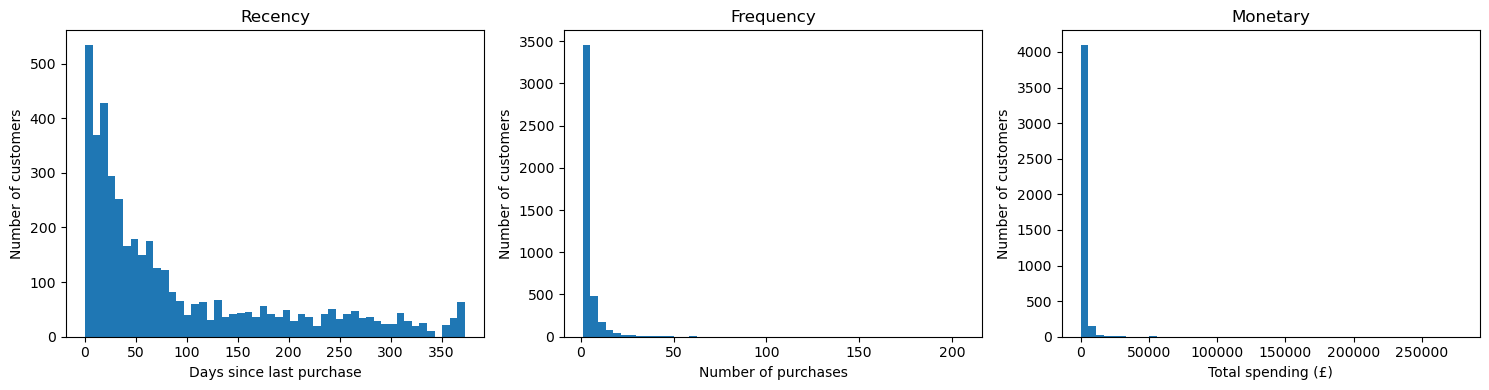

In [57]:
# Plot the distribution of Recency, Frequency, and Monetary
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
labels = {"Recency": "Days since last purchase", "Frequency": "Number of purchases", "Monetary": "Total spending (£)"}
for ax, col in zip(axes, ["Recency", "Frequency", "Monetary"]):
    ax.hist(rfm[col], bins=50)
    ax.set_title(col)
    ax.set_xlabel(labels[col])
    ax.set_ylabel("Number of customers")
plt.tight_layout()
plt.show()

**What the charts show:** all three distributions are stretched to the right. Recency is highest for the most recent customers, falls over the first 100 days or so, and then stays roughly flat, so customers are spread across the whole year. Frequency and Monetary are packed at low values: most customers bought a few times and spent little, and a handful of customers sit far out to the right, far from everyone else. K-Means groups customers by distance, so these stretched shapes need attention before clustering.

In [58]:
# Measure how stretched each distribution is (skewness: 0 is symmetric, above 1 is strongly stretched to the right)
rfm.skew().round(2)

Recency       1.25
Frequency    11.94
Monetary     21.54
dtype: float64

In [59]:
# Share of total spending held by the top 1%, 10%, and 20% of customers by Monetary, and the share of customers who bought exactly once
spending = rfm["Monetary"].sort_values(ascending=False)
for share in [0.01, 0.10, 0.20]:
    n_top = int(round(len(spending) * share))
    print(f"Top {share:.0%} of customers ({n_top}):", round(spending.head(n_top).sum() / spending.sum(), 3))
print("Bought exactly once:", round((rfm["Frequency"] == 1).mean(), 3))

Top 1% of customers (43): 0.302
Top 10% of customers (432): 0.601
Top 20% of customers (864): 0.737
Bought exactly once: 0.346


### Descriptive statistics result

All figures are for the 4,320 customers in the customer table.

- **Typical customer vs average customer:** about half of the customers made 2 purchases or fewer and spent £650.42 or less, but the average customer made 4.26 purchases and spent £1,914.27. A small group of heavy buyers pulls the averages up.
- **Purchase value:** the average purchase invoice is worth £470.58 (median £301.69).
- **Customer lifetime value (historical):** £1,914.27 per customer on average. A customer's purchases add up to £2,002.81 on average, and cancellations take away £88.54, which leaves £1,914.27.
- **Recency:**  half of the customers made their most recent purchase in the last 50 days of the data, and the rest are spread out up to 373 days.
- **One-time buyers:** 34.6% of customers bought exactly once.
- **Concentration:** the top 10% of customers account for 60.1% of total spending, and the top 20% for 73.7%.

Frequency and Monetary are strongly skewed (skewness, how stretched a distribution is to the right, is 11.94 and 21.54, against 1.25 for Recency), so they are prepared in the next section before K-Means.

### Preparing the features for K-Means

K-Means groups customers by distance, so it is sensitive to very stretched values and to features measured on different scales.

**What I do**
- Check that the largest customers are genuine before keeping them.
- Apply log(1 + x) to Frequency and Monetary, which are strongly stretched (skewness 11.94 and 21.54). Recency stays in days (skewness 1.25).
- Standardize all three features with StandardScaler (average 0, standard deviation 1), so that each counts equally in the distance.
- The groups are built on these prepared values. The group profiles later are reported in the original units.

In [60]:
# Show the 10 customers with the highest Monetary, to check that they look like real heavy buyers
rfm.sort_values("Monetary", ascending=False).head(10)

,Recency,Frequency,Monetary
CustomerID,,,
14646,1,72,278778.02
18102,0,60,259657.30
17450,8,46,189575.53
14911,1,198,128768.24
12415,24,20,123638.18
14156,9,54,113685.77
17511,2,31,88138.20
16684,4,28,65920.12
13694,3,50,62961.54


In [61]:
# Show how far the largest value of each feature is from its average, in standard deviations
((rfm - rfm.mean()) / rfm.std()).max().round(1)

Recency       2.8
Frequency    26.4
Monetary     33.3
dtype: float64

In [62]:
# Import numpy for the log transform and StandardScaler for standardizing
import numpy as np
from sklearn.preprocessing import StandardScaler

In [63]:
# Apply log(1 + x) to Frequency and Monetary (Recency stays in days), then check the skewness of the three features
rfm_log = rfm.copy()
rfm_log["Frequency"] = np.log1p(rfm_log["Frequency"])
rfm_log["Monetary"] = np.log1p(rfm_log["Monetary"])
rfm_log.skew().round(2)

Recency      1.25
Frequency    1.21
Monetary     0.37
dtype: float64

In [64]:
# Standardize the three features (average 0, standard deviation 1) so that each counts equally in the distance
scaler = StandardScaler()
rfm_scaled = pd.DataFrame(scaler.fit_transform(rfm_log), index=rfm_log.index, columns=rfm_log.columns)
rfm_scaled.describe().round(2)

,Recency,Frequency,Monetary
count,4320.00,4320.00,4320.00
mean,0.00,0.00,-0.00
std,1.00,1.00,1.00
min,-0.92,-0.95,-4.16
25%,-0.75,-0.95,-0.68
50%,-0.42,-0.36,-0.06
75%,0.50,0.66,0.66
max,2.81,5.85,4.79


In [65]:
# Show how strongly the three transformed features move together (1 = rise together perfectly, 0 = no relationship, -1 = one rises when the other falls)
rfm_log.corr().round(2)

,Recency,Frequency,Monetary
Recency,1.00,-0.47,-0.44
Frequency,-0.47,1.00,0.81
Monetary,-0.44,0.81,1.00


### Feature preparation result

- **The largest customers are kept because they are real repeat buyers:** the 10 highest spenders have 20 to 198 purchases each and last bought within 38 days of the reference date.
- **The log transform reduced the pull of very large values.** The largest Frequency and Monetary values were 26.4 and 33.3 standard deviations above the average, and after the transform they are 5.85 and 4.79. Skewness fell from 11.94 to 1.21 for Frequency and from 21.54 to 0.37 for Monetary (Recency, untouched, is 1.25).
- **Standardizing** puts the three features on the same scale (average 0, standard deviation 1), so none of them dominates the distance only because its numbers are bigger.

**Things to keep in mind**
- Frequency and Monetary move together: the correlation is 0.81 after the log transform (0.57 on the original values). Customers who buy often tend to spend a lot, so K-Means sees much of the same information twice. I keep all three RFM features, as the framework defines them. After the clustering, I'll compare the groups with and without Frequency to see how much this matters.
- Monetary has a low end: the lowest standardized value is -4.16 (customers whose net spending is as low as £2.90). K-Means could place these customers in a very small group of their own, or in a larger group of low spenders. The group profiles below show which happens.

## Choosing the Number of Groups

K-Means needs the number of groups (K) in advance. I'll try K from 1 to 10 and look at two measures:
- **Elbow Method:** how spread out the customers are inside their groups. It always falls as K grows, so the point where the fall slows down (the "elbow") suggests a sensible K.
- **Silhouette score:** how well separated the groups are, from -1 to 1 (higher is better).

In [66]:
# Import KMeans and the silhouette score
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [67]:
# Fit K-Means for 1 to 10 groups and record the inertia (how spread out each group is) and the silhouette score (how well separated the groups are)
results = []
for k in range(1, 11):
    model = KMeans(n_clusters=k, n_init=10, random_state=42).fit(rfm_scaled)
    silhouette = silhouette_score(rfm_scaled, model.labels_) if k > 1 else None
    results.append((k, model.inertia_, silhouette))
elbow = pd.DataFrame(results, columns=["K", "Inertia", "Silhouette"])
elbow.round(3)

,K,Inertia,Silhouette
0,1,12960.000,NaN
1,2,6836.001,0.406
2,3,4270.075,0.415
3,4,3211.236,0.381
4,5,2732.122,0.344
5,6,2367.204,0.331
6,7,2139.022,0.301
7,8,1937.144,0.300
8,9,1792.026,0.285
9,10,1661.451,0.282


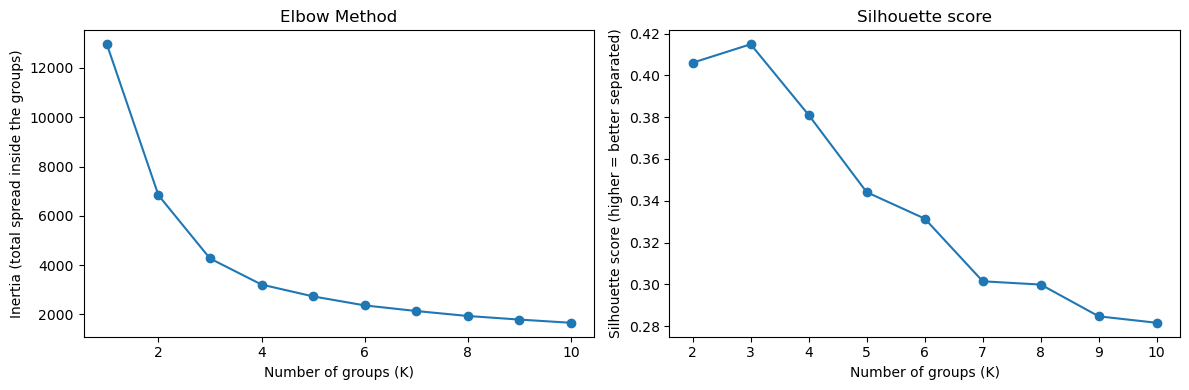

In [68]:
# Plot the Elbow curve (inertia) and the silhouette score for each number of groups
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(elbow["K"], elbow["Inertia"], marker="o")
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of groups (K)")
axes[0].set_ylabel("Inertia (total spread inside the groups)")
axes[1].plot(elbow["K"][1:], elbow["Silhouette"][1:], marker="o")
axes[1].set_title("Silhouette score")
axes[1].set_xlabel("Number of groups (K)")
axes[1].set_ylabel("Silhouette score (higher = better separated)")
plt.tight_layout()
plt.savefig("images/choosing_k.png", dpi=150, bbox_inches="tight")
plt.show()

### Choice of K

- **Elbow Method:** inertia falls steeply up to K = 3 (from 12,960 at K = 1 to 4,270) and more slowly afterwards (3,211 at K = 4, 2,732 at K = 5). The bend is gradual, so K = 3 and K = 4 are both plausible.
- **Silhouette score:** highest at K = 3 (0.415), against 0.406 at K = 2 and 0.381 at K = 4.
- **Decision: K = 3.** It has the highest silhouette score and sits at a bend of the elbow curve.
- **Limitation:** a silhouette score of 0.415 is far below 1, so the groups overlap. Customers form a continuum, and the segments describe tendencies, not sharp boundaries.

## K-Means Clustering

With K = 3, K-Means is fitted on the prepared features. Each customer gets a group label, which is added to a copy of the customer table in its original units, so the groups can be described in days, purchases, and pounds.

In [69]:
# Fit K-Means with 3 groups on the prepared features and add each customer's group to a copy of the customer table (original units)
final_model = KMeans(n_clusters=3, n_init=10, random_state=42).fit(rfm_scaled)
segments = rfm.copy()
segments["Cluster"] = final_model.labels_
segments["Cluster"].value_counts().sort_index()

Cluster
0     978
1    1310
2    2032
Name: count, dtype: int64

In [70]:
# Profile each group in the original units: number of customers, average and median Recency, Frequency, and Monetary, and share of total spending
profile = segments.groupby("Cluster").agg(
    Customers=("Recency", "size"),
    Recency_mean=("Recency", "mean"),
    Frequency_mean=("Frequency", "mean"),
    Monetary_mean=("Monetary", "mean"),
    Recency_median=("Recency", "median"),
    Frequency_median=("Frequency", "median"),
    Monetary_median=("Monetary", "median"),
    Total_spending=("Monetary", "sum"),
)
profile["Share_of_customers_%"] = profile["Customers"] / profile["Customers"].sum() * 100
profile["Share_of_spending_%"] = profile["Total_spending"] / profile["Total_spending"].sum() * 100
profile.round(1).T

Cluster,0,1,2
Customers,978.0,1310.0,2032.0
Recency_mean,254.8,29.2,54.3
Frequency_mean,1.4,9.8,2.0
Monetary_mean,390.2,5092.5,598.8
Recency_median,252.0,17.0,45.0
Frequency_median,1.0,7.0,2.0
Monetary_median,271.5,2475.6,499.1
Total_spending,381569.7,6671208.8,1216858.8
Share_of_customers_%,22.6,30.3,47.0
Share_of_spending_%,4.6,80.7,14.7


In [71]:
# Give each group a descriptive name, based on the profile table above
names = {0: "Lapsed low spenders", 1: "Best customers", 2: "Occasional recent buyers"}
segments["Segment"] = segments["Cluster"].map(names)
segments["Segment"].value_counts()

Segment
Occasional recent buyers    2032
Best customers              1310
Lapsed low spenders          978
Name: count, dtype: int64

### Group profiles

K-Means found three groups. The medians are quoted because Monetary is skewed (the full table above also shows the means).

- **Best customers (1,310 customers, 30.3%):** bought recently (median 17 days before the reference date), buy often (median 7 purchases), and spend the most (median £2,476). They account for 80.7% of total spending.
- **Occasional recent buyers (2,032 customers, 47.0%):** bought fairly recently (median 45 days), but only about twice (median 2 purchases) and spend modestly (median £499). They account for 14.7% of total spending.
- **Lapsed low spenders (978 customers, 22.6%):** last bought long ago (median 252 days, more than eight months), usually once (median 1 purchase), and spent little (median £271). They account for 4.6% of total spending.

**Key finding:** three in ten customers produce four fifths of the spending.

None of the groups is small (the smallest has 978 customers), so the customers with the lowest spending are inside larger groups, not a group of their own.

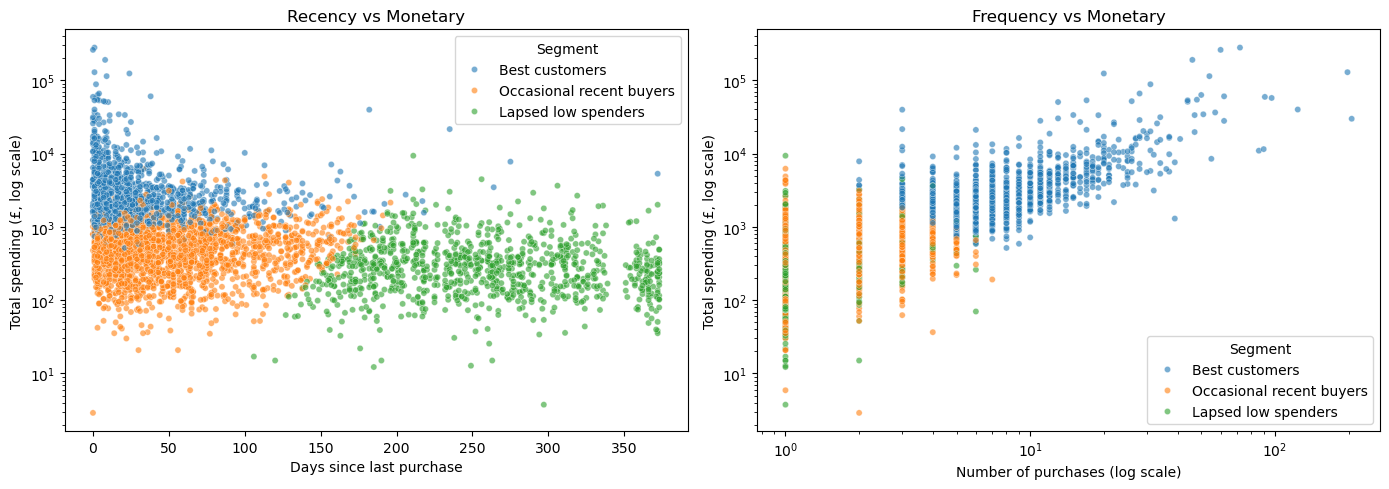

In [72]:
# Scatter plots of the groups: Recency against Monetary, and Frequency against Monetary (log scales so the largest customers do not hide the rest)
order = ["Best customers", "Occasional recent buyers", "Lapsed low spenders"]
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(data=segments, x="Recency", y="Monetary", hue="Segment", hue_order=order, alpha=0.6, s=20, ax=axes[0])
axes[0].set_yscale("log")
axes[0].set_xlabel("Days since last purchase")
axes[0].set_ylabel("Total spending (£, log scale)")
axes[0].set_title("Recency vs Monetary")
sns.scatterplot(data=segments, x="Frequency", y="Monetary", hue="Segment", hue_order=order, alpha=0.6, s=20, ax=axes[1])
axes[1].set_xscale("log")
axes[1].set_yscale("log")
axes[1].set_xlabel("Number of purchases (log scale)")
axes[1].set_ylabel("Total spending (£, log scale)")
axes[1].set_title("Frequency vs Monetary")
plt.tight_layout()
os.makedirs("images", exist_ok=True)
plt.savefig("images/scatter_plots.png", dpi=150, bbox_inches="tight")
plt.show()

**What the scatter plots show:** each dot is a customer, coloured by segment.
- **Recency vs Monetary:** Best customers are at the top left (recent and high spending). Lapsed low spenders are on the right, at least 106 days since their last purchase, with lower spending. Occasional recent buyers fill the middle band.
- **Frequency vs Monetary:** spending rises with the number of purchases, which is expected because Monetary adds up the purchases.
- **The groups overlap** (for example, Lapsed low spenders and Occasional recent buyers between 106 and 196 days), which fits the silhouette score of 0.415: the segments describe tendencies, not sharp boundaries.

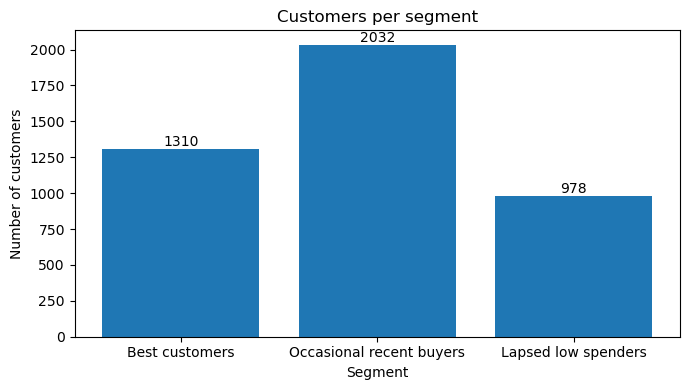

In [73]:
# Bar chart: number of customers in each segment
order = ["Best customers", "Occasional recent buyers", "Lapsed low spenders"]
counts = segments["Segment"].value_counts().reindex(order)
fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(counts.index, counts.values)
ax.bar_label(bars)
ax.set_xlabel("Segment")
ax.set_ylabel("Number of customers")
ax.set_title("Customers per segment")
plt.tight_layout()
plt.show()

**What the bar chart shows:** the number of customers in each segment: 2,032 Occasional recent buyers (47.0%), 1,310 Best customers (30.3%), and 978 Lapsed low spenders (22.6%). Best customers are less than a third of the customers but account for 80.7% of total spending.

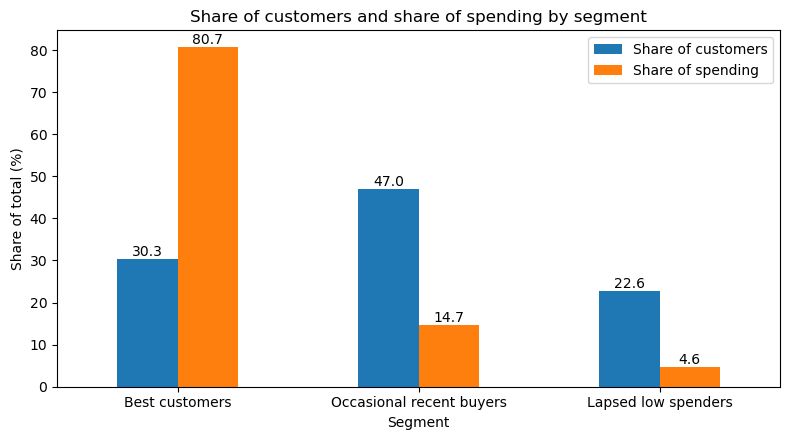

In [74]:
# share of customers and share of spending for each segment
os.makedirs("images", exist_ok=True)
order = ["Best customers", "Occasional recent buyers", "Lapsed low spenders"]
shares = profile.rename(index=names).loc[order, ["Share_of_customers_%", "Share_of_spending_%"]]
ax = shares.plot(kind="bar", figsize=(8, 4.5), rot=0)
ax.set_xlabel("Segment")
ax.set_ylabel("Share of total (%)")
ax.set_title("Share of customers and share of spending by segment")
ax.legend(["Share of customers", "Share of spending"])
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f")
plt.tight_layout()
plt.savefig("images/segments_customers_vs_spending.png", dpi=150)
plt.show()

**What the chart shows:** Best customers are 30.3% of customers but 80.7% of total spending. Occasional recent buyers are the largest segment, 47.0% of customers and 14.7% of spending. Lapsed low spenders are 22.6% of customers and 4.6% of spending.

In [75]:
# Show the smallest and largest Recency, Frequency, and Monetary in each segment
segments.groupby("Segment")[["Recency", "Frequency", "Monetary"]].agg(["min", "max"]).round(1)

Recency      Frequency      Monetary          
                             min  max       min  max      min       max
Segment                                                                
Best customers                 0  372         2  206    515.7  278778.0
Lapsed low spenders          106  373         1    6      3.8    9338.4
Occasional recent buyers       0  196         1    7      2.9    6207.7

### Scatter plots and group sizes

- **Recency vs Monetary:** Best customers are at the top left (recent, high spending), Lapsed low spenders are mostly on the right at lower spending, and Occasional recent buyers fill the middle band. Lapsed low spenders start at 106 days and Occasional recent buyers reach 196 days, so those two overlap between these values.
- **Frequency vs Monetary:** spending rises with the number of purchases, which is expected because Monetary adds up the purchases. Best customers have 2 to 206 purchases, Occasional recent buyers 1 to 7, and Lapsed low spenders 1 to 6.
- **The groups overlap,** for example in spending: Best customers start at £516 and Occasional recent buyers reach £6,208. This matches the silhouette score of 0.415: the segments describe tendencies, not sharp boundaries.
- **Group sizes:** Occasional recent buyers are the largest segment (2,032 customers, 47.0%) and Lapsed low spenders the smallest (978, 22.6%).

In [76]:
# Count Best customers who last bought as long ago as the most recent lapsed customer, and the share of once-only buyers in Occasional recent buyers
best = segments[segments["Segment"] == "Best customers"]
lapsed_min = segments[segments["Segment"] == "Lapsed low spenders"]["Recency"].min()
print(lapsed_min, len(best[best["Recency"] >= lapsed_min]), round(len(best[best["Recency"] >= lapsed_min]) / len(best), 3))
occasional = segments[segments["Segment"] == "Occasional recent buyers"]
print(round((occasional["Frequency"] == 1).mean(), 3))

106 58 0.044
0.382


## Insights and Recommendations

"Spending" below is a customer's total spending after subtracting cancellations (Monetary), which is how the data measures revenue.

**Answers to the business questions**
1. **Which segments exist?** Three: Best customers, Occasional recent buyers, and Lapsed low spenders.
2. **Which bring the most revenue?** Best customers: 30.3% of customers and 80.7% of total spending.
3. **Which are at risk of lapsing?**
   - Already lapsed: Lapsed low spenders. The middle customer in this segment last bought 252 days before the reference date.
   - At risk: Occasional recent buyers. They bought recently (the middle customer 45 days before), but 38.2% bought only once, so their next purchase is not secured.
   - Valuable but gone quiet: 58 Best customers (4.4% of the segment) last bought 106 days or more before the reference date. 106 days is the shortest gap among Lapsed low spenders.

   The data covers one year, so "at risk" describes a pattern, not a prediction.
4. **What marketing action fits each segment?** See the table below.

**Recommended actions** 

| Segment | Action | How to measure it |
|---|---|---|
| Best customers (80.7% of spending) | Protect them with a loyalty programme or early access, and contact the 58 who have gone quiet first. Many customers of this retailer are wholesalers, so an account-style approach (a dedicated contact, volume terms) may fit better than consumer perks. The data has no customer type, so this is untested. | Share of these customers who still buy in the next period |
| Occasional recent buyers (47.0% of customers, 14.7% of spending) | Encourage a second and third purchase, for example with a follow-up offer after a purchase or recommendations based on what they bought. | Share who make another purchase within a set period |
| Lapsed low spenders (22.6% of customers, 4.6% of spending) | Low-cost win-back only, such as a single email. Their median spending is £271 and they typically bought once. | Share who buy again |

**Limits:** the segments overlap (silhouette score 0.415) and the data covers one year, so they are a starting point for testing and not fixed labels.

## Robustness Checks

Two checks of how much earlier choices affect the segments. In each, K-Means is rerun with 3 groups on the changed features, and the new groups are compared with the main segments. Group numbers are arbitrary, so the new groups are first matched to the main segments. The adjusted Rand index measures how much two groupings agree (1 = identical, close to 0 = no better than chance).

In [77]:
# Import the tools to compare two groupings
from sklearn.metrics import adjusted_rand_score
from scipy.optimize import linear_sum_assignment

In [78]:
# Helper: fit K-Means with 3 groups on log-transformed and standardized features, and compare the new groups with the main segments
def compare_with_main(features, label):
    prepared = features.copy()
    for col in ["Frequency", "Monetary"]:
        if col in prepared:
            prepared[col] = np.log1p(prepared[col])
    prepared = StandardScaler().fit_transform(prepared)
    new_labels = KMeans(n_clusters=3, n_init=10, random_state=42).fit(prepared).labels_
    table = pd.crosstab(segments["Segment"], new_labels, rownames=["Main segment"], colnames=["Group in the check"])
    rows, cols = linear_sum_assignment(-table.values)
    same = table.values[rows, cols].sum()
    table = table.rename(columns={table.columns[c]: table.index[r] for r, c in zip(rows, cols)})[list(table.index)]
    print("Check:", label)
    print("Customers in the same segment:", same, "of", len(segments), f"({same / len(segments):.1%})")
    print("Adjusted Rand index:", round(adjusted_rand_score(segments["Segment"], new_labels), 3))
    return table

In [79]:
# Check 1 (Decision 1): rebuild Monetary from purchases only (cancellations not subtracted) for the same customers, and compare the groups
purchase_only = purchases[purchases["CustomerID"].isin(rfm.index)].groupby("CustomerID")["Revenue"].sum().round(2)
features_a = rfm.copy()
features_a["Monetary"] = purchase_only
print((features_a["Monetary"] != rfm["Monetary"]).sum(), "customers have a different Monetary")
compare_with_main(features_a, "Monetary from purchases only")

1492 customers have a different Monetary
Check: Monetary from purchases only
Customers in the same segment: 4299 of 4320 (99.5%)
Adjusted Rand index: 0.985


Group in the check,Best customers,Lapsed low spenders,Occasional recent buyers
Main segment,,,
Best customers,1309,1,0
Lapsed low spenders,0,974,4
Occasional recent buyers,13,3,2016


In [80]:
# Check 2 (feature overlap): leave out Frequency and compare the groups
compare_with_main(rfm[["Recency", "Monetary"]], "Without Frequency")

Check: Without Frequency
Customers in the same segment: 3915 of 4320 (90.6%)
Adjusted Rand index: 0.723


Group in the check,Best customers,Lapsed low spenders,Occasional recent buyers
Main segment,,,
Best customers,1253,6,51
Lapsed low spenders,3,955,20
Occasional recent buyers,301,24,1707


##### Results :

**Check 1: cancellations (Decision 1).** Monetary is rebuilt from purchases only (Option A) for the same 4,320 customers, with the log transform and standardization unchanged. 1,492 customers have a different Monetary (customer 16446 has £168,472.50 under Option A and £2.90 under Option B), but 4,299 of 4,320 customers (99.5%) stay in the same segment (adjusted Rand index 0.985). The choice between the two options changes the segment of only 21 customers. Option B is kept because it measures spending correctly, and the segments are the same either way.

**Check 2: feature overlap.** With Frequency left out, 3,915 of 4,320 customers (90.6%) stay in the same segment (adjusted Rand index 0.723). Of the 405 customers that move, 301 are Occasional recent buyers who join the Best customers group, so the boundary between these two segments depends on Frequency. The segments are mostly stable, and the overlap between Frequency and Monetary matters mainly for customers at that boundary.